In [1]:
import sys
from pathlib import Path
_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(_root / "scripts"))

import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from glacier_utils import (PROC, TAB, SIZE_LABELS, SIZE_COLORS, add_size_class, set_style, save_fig)
set_style()

gdf = gpd.read_file(PROC / "nepal_glaciers.gpkg", layer="glaciers")
gdf = add_size_class(gdf)

nepal = gdf[gdf["centroid_in_nepal"]].copy()       # primary dataset: centre point inside Nepal
tb = gdf[gdf["transboundary"]].copy()              # transboundary glaciers
print(f"Primary dataset (centre inside Nepal): {len(nepal):,} glaciers, {nepal.area_km2.sum():,.1f} km2")
print(f"Transboundary                        : {len(tb):,} glaciers, {tb.area_km2.sum():,.1f} km2")
print("Unclassified glaciers:", gdf["size_class"].isna().sum())

Primary dataset (centre inside Nepal): 4,480 glaciers, 4,244.8 km2
Transboundary                        : 199 glaciers, 1,041.6 km2
Unclassified glaciers: 0


In [2]:
def class_table(df):
    t = df.groupby("size_class", observed=False).agg(
        n=("rgi_id", "size"), area_km2=("area_km2", "sum"), mean_km2=("area_km2", "mean"))
    t["pct_count"] = 100 * t["n"] / t["n"].sum()
    t["pct_area"] = 100 * t["area_km2"] / t["area_km2"].sum()
    return t

t_core, t_tb, t_all = class_table(nepal), class_table(tb), class_table(gdf)

print("PRIMARY: centre point inside Nepal")
print(t_core.round(2).to_string())

print("\nSENSITIVITY: centre-inside vs any-overlap (glacier counts and area)")
cmp = pd.DataFrame({
    "n_core": t_core["n"], "n_transb": t_tb["n"], "n_any": t_all["n"],
    "km2_core": t_core["area_km2"], "km2_transb": t_tb["area_km2"], "km2_any": t_all["area_km2"],
})
cmp["area_increase_%"] = 100 * cmp["km2_transb"] / cmp["km2_core"]
print(cmp.round(1).to_string())

t_core.round(3).to_csv(TAB / "size_classes_nepal.csv")
cmp.round(3).to_csv(TAB / "size_classes_sensitivity.csv")

PRIMARY: centre point inside Nepal
               n  area_km2  mean_km2  pct_count  pct_area
size_class                                               
<0.5        3092    513.39      0.17      69.02     12.09
0.5–1        608    426.93      0.70      13.57     10.06
1–5          640   1325.46      2.07      14.29     31.23
5–10          69    485.73      7.04       1.54     11.44
10–50         67   1216.81     18.16       1.50     28.67
>50            4    276.45     69.11       0.09      6.51

SENSITIVITY: centre-inside vs any-overlap (glacier counts and area)
            n_core  n_transb  n_any  km2_core  km2_transb  km2_any  area_increase_%
size_class                                                                         
<0.5          3092        55   3147     513.4        11.4    524.8              2.2
0.5–1          608        26    634     426.9        19.4    446.3              4.5
1–5            640        69    709    1325.5       159.6   1485.1             12.0
5–10        

In [3]:
a = nepal["area_km2"].sort_values()
cum_asc = a.cumsum() / a.sum()

stats = pd.Series({
    "n_glaciers": len(a),
    "total_area_km2": a.sum(),
    "mean_km2": a.mean(),
    "median_km2": a.median(),
    "max_km2": a.max(),
    "p10_km2": a.quantile(0.10),
    "p25_km2": a.quantile(0.25),
    "p75_km2": a.quantile(0.75),
    "p90_km2": a.quantile(0.90),
    "p99_km2": a.quantile(0.99),
    "pct_glaciers_below_1km2": 100 * (a < 1).mean(),
    "pct_area_in_glaciers_below_1km2": 100 * a[a < 1].sum() / a.sum(),
    # Area-weighted view: the glacier size below which half of all ice area lies
    "area_weighted_median_km2": a[cum_asc >= 0.5].iloc[0],
    "n_largest_glaciers_for_50pct_area": int((a.sort_values(ascending=False).cumsum() / a.sum() < 0.5).sum() + 1),
    "pct_area_in_10_largest": 100 * a.nlargest(10).sum() / a.sum(),
})
print(stats.round(2).to_string())
stats.round(3).to_csv(TAB / "size_summary_stats.csv", header=["value"])

print("\nFive largest glaciers (centre inside Nepal):")
print(nepal.nlargest(5, "area_km2")[["rgi_id", "glac_name", "area_km2", "zmin_m", "zmax_m", "src_year"]].to_string(index=False))
print("\nFive largest transboundary glaciers:")
print(tb.nlargest(5, "area_km2")[["rgi_id", "glac_name", "area_km2", "zmin_m", "zmax_m", "src_year"]].to_string(index=False))

n_glaciers                           4480.00
total_area_km2                       4244.78
mean_km2                                0.95
median_km2                              0.23
max_km2                                84.50
p10_km2                                 0.04
p25_km2                                 0.09
p75_km2                                 0.66
p90_km2                                 1.79
p99_km2                                13.24
pct_glaciers_below_1km2                82.59
pct_area_in_glaciers_below_1km2        22.15
area_weighted_median_km2                4.22
n_largest_glaciers_for_50pct_area     172.00
pct_area_in_10_largest                 11.76

Five largest glaciers (centre inside Nepal):
                 rgi_id        glac_name  area_km2    zmin_m    zmax_m  src_year
RGI2000-v7.0-G-15-07885              NaN 84.504004 4602.5093 7435.1885      1994
RGI2000-v7.0-G-15-08305         Ngojumba 70.153762 4694.0980 8146.7890      1999
RGI2000-v7.0-G-15-07868           Ya

Saved outputs/figures/02_size_distribution.png and .svg


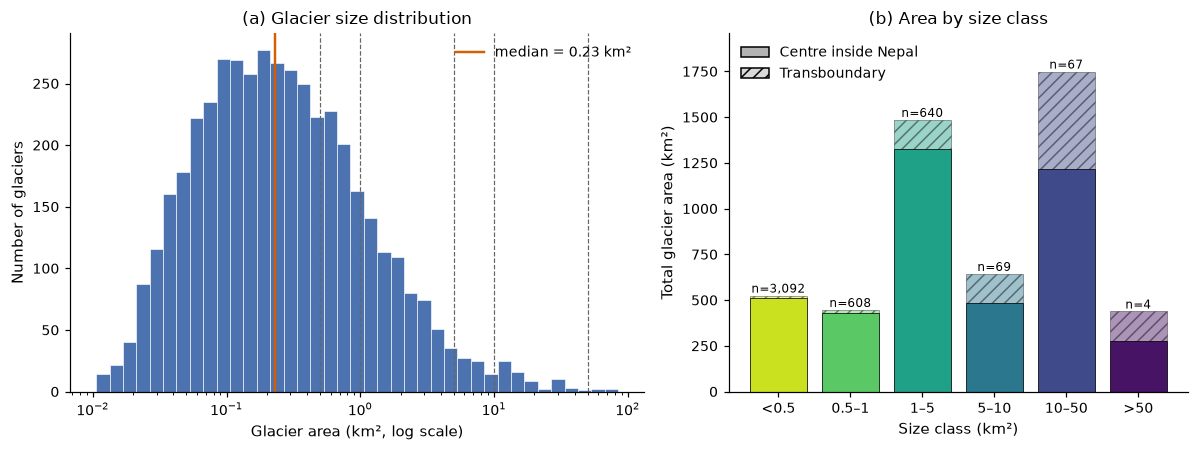

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})

# (a) Histogram on a log-spaced x axis
edges = np.logspace(np.log10(nepal["area_km2"].min()), np.log10(nepal["area_km2"].max()), 40)
ax1.hist(nepal["area_km2"], bins=edges, color="#4C72B0", edgecolor="white", linewidth=0.4)
ax1.set_xscale("log")
for b in (0.5, 1, 5, 10, 50):
    ax1.axvline(b, color="0.4", ls="--", lw=0.8)
ax1.axvline(nepal["area_km2"].median(), color="#D55E00", lw=1.6,
            label=f"median = {nepal['area_km2'].median():.2f} km²")
ax1.set_xlabel("Glacier area (km², log scale)")
ax1.set_ylabel("Number of glaciers")
ax1.set_title("(a) Glacier size distribution")
ax1.legend(frameon=False)

# (b) Area by size class: solid = centre inside Nepal, hatched = transboundary
x = np.arange(len(SIZE_LABELS))
ax2.bar(x, t_core["area_km2"], color=SIZE_COLORS, edgecolor="k", linewidth=0.5)
ax2.bar(x, t_tb["area_km2"], bottom=t_core["area_km2"], color=SIZE_COLORS, alpha=0.45,
        hatch="///", edgecolor="k", linewidth=0.5)
for xi, (n, ac) in enumerate(zip(t_core["n"], t_core["area_km2"] + t_tb["area_km2"])):
    ax2.text(xi, ac, f"n={n:,}", ha="center", va="bottom", fontsize=8)
ax2.set_xticks(x, SIZE_LABELS)
ax2.set_xlabel("Size class (km²)")
ax2.set_ylabel("Total glacier area (km²)")
ax2.set_title("(b) Area by size class")
ax2.set_ylim(0, (t_core["area_km2"] + t_tb["area_km2"]).max() * 1.12)
from matplotlib.patches import Patch
ax2.legend(handles=[Patch(facecolor="0.7", edgecolor="k", label="Centre inside Nepal"),
                    Patch(facecolor="0.85", edgecolor="k", hatch="///", label="Transboundary")],
           frameon=False, loc="upper left")

fig.tight_layout()
save_fig(fig, "02_size_distribution")
plt.show()